# Shared TX + Multilingual Receiver — using DeepSC `all` functions

This version intentionally reuses the functions already present in the **DeepSC `all` branch** instead of duplicating them inside the notebook.

Reused directly from the repository:

- `EurMultilingualDatasetBPE`
- `collate_multilingual_bpe`
- `load_bpe`
- `SeqtoTextBPE`
- `transmitter`
- `greedy_decode`
- `beam_decode`
- `send_through_channel`
- `load_teacher`
- `setup_seed`
- `DeepSCMetrics`

The only experiment-specific logic kept here is:

```text
src
 ↓
transmitter(...)
 ↓
Tx_sig
 ↓
send_through_channel(...)   ← ONCE
 ↓
Rx_sig
 ├── greedy/beam <EN>
 ├── greedy/beam <PT>
 ├── greedy/beam <ES>
 └── greedy/beam <FR>
```

The **same `Rx_sig`** is reused for all target languages.


## 1. Imports

Run this notebook from the root of the DeepSC repository while checked out on branch `all`.


In [1]:
from __future__ import annotations

import json
import os
from functools import partial
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from dataset_multilingual import (
    EurMultilingualDatasetBPE,
    collate_multilingual_bpe,
)

from models.transceiver import DeepSC

from utils.bpe_utils import (
    SeqtoTextBPE,
    beam_decode,
    greedy_decode,
    load_bpe,
    transmitter,
)

from utils.model_utils import (
    load_teacher,
    send_through_channel,
    setup_seed,
)

from metrics.metrics_bpe import DeepSCMetrics


/home/prinako/External/WorkSpace/PGCC/DeepSC/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configuration

In [2]:
# ------------------------------------------------------------
# Dataset produced by process_multilingual_deepsc.py
# Use the EXACT preprocessing directory.
# ------------------------------------------------------------
DATA_DIR = "data/train/europarl_bpe/2026-09-19"

# ------------------------------------------------------------
# Teacher/model checkpoints
# ------------------------------------------------------------
ENCODER_CHECKPOINT = "results/base_model/2026-09-28/encoder_46.pth"
DECODER_CHECKPOINT = "results/base_model/2026-09-28/decoder_46.pth"

# Optional teacher run config from main_multi_vocab.py
RUN_CONFIG = None
# Example:
# RUN_CONFIG = "checkpoints/.../run_config.json"

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------
SPLIT = "val"                   # use "test" only for final evaluation
LANGUAGES = ("en", "pt", "es", "fr")

CHANNEL = "Rayleigh"
SNR_DB = [0,2, 4,6, 8,10, 12,14, 16,18, 20]
TRIALS = 1

DECODE = "beam"               # "greedy" or "beam"
BEAM_SIZE = 5
LENGTH_PENALTY = 0.7

BATCH_SIZE = 32
NUM_WORKERS = 0
SEED = 48

MAX_SAMPLES = 20                # None = whole split

# Metrics can be expensive because semantic similarity loads a transformer.
COMPUTE_METRICS = True
SEMANTIC_MODEL = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"

OUTPUT_DIR = "results/multilingual_shared_tx"


## 3. Read preprocessing/model configuration

The new synchronized preprocessing stores the authoritative sequence length in `preprocessing_config.json`.


In [3]:
def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


preprocessing_path = os.path.join(
    DATA_DIR,
    "preprocessing_config.json",
)

vocab_path = os.path.join(
    DATA_DIR,
    "vocab_bpe.json",
)

tokenizer_path = os.path.join(
    DATA_DIR,
    "tokenizer_bpe.model",
)

preprocessing_config = read_json(preprocessing_path)

if RUN_CONFIG is None:
    candidate = os.path.join(
        os.path.dirname(ENCODER_CHECKPOINT),
        "run_config.json",
    )
    run_config = read_json(candidate) if os.path.exists(candidate) else {}
else:
    run_config = read_json(RUN_CONFIG)

MAX_LEN = int(
    run_config.get(
        "max_length",
        preprocessing_config.get("max_seq_len", 64),
    )
)

NUM_LAYERS = int(run_config.get("num_layers", 8))
NUM_HEADS = int(run_config.get("num_heads", 16))
D_MODEL = int(run_config.get("d_model", 128))
DFF = int(run_config.get("dff", 512))
DROPOUT = float(run_config.get("dropout", 0.1))

print("Preprocessing max_seq_len:", preprocessing_config.get("max_seq_len"))
print("Model max length         :", MAX_LEN)
print("Teacher layers / heads   :", NUM_LAYERS, "/", NUM_HEADS)


Preprocessing max_seq_len: 64
Model max length         : 64
Teacher layers / heads   : 8 / 16


## 4. Load BPE with the repository helper

`load_bpe()` already checks the fixed IDs for PAD/START/END/UNK and EN/PT/ES/FR.


In [4]:
token_to_idx, sp = load_bpe(
    vocab_path,
    tokenizer_path,
)

VOCAB_SIZE = len(token_to_idx)

PAD_IDX = int(token_to_idx["<PAD>"])
START_IDX = int(token_to_idx["<START>"])
END_IDX = int(token_to_idx["<END>"])

LANG_ID = {
    "en": int(token_to_idx["<EN>"]),
    "pt": int(token_to_idx["<PT>"]),
    "es": int(token_to_idx["<ES>"]),
    "fr": int(token_to_idx["<FR>"]),
}

converter = SeqtoTextBPE(
    vocb_dictionary=token_to_idx,
    end_idx=END_IDX,
    tokenizer_model=tokenizer_path,
)

print("Vocabulary size:", VOCAB_SIZE)
print("Language IDs:", LANG_ID)


BPE CHECK
SentencePiece vocab : 32000
JSON vocab          : 32000
<PAD>    JSON=0     SP=0    
<START>  JSON=1     SP=1    
<END>    JSON=2     SP=2    
<UNK>    JSON=3     SP=3    
<EN>     JSON=4     SP=4    
<PT>     JSON=5     SP=5    
<ES>     JSON=6     SP=6    
<FR>     JSON=7     SP=7    
Vocabulary size: 32000
Language IDs: {'en': 4, 'pt': 5, 'es': 6, 'fr': 7}


## 5. Load the synchronized dataset

This directly reuses `EurMultilingualDatasetBPE` and `collate_multilingual_bpe`.


In [5]:
dataset = EurMultilingualDatasetBPE(
    split=SPLIT,
    data_dir=DATA_DIR,
    languages=LANGUAGES,
)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    collate_fn=partial(
        collate_multilingual_bpe,
        pad_idx=PAD_IDX,
    ),
)

print("Split:", SPLIT)
print("Samples:", len(dataset))


Split: val
Samples: 231881


## 6. Build and load the Teacher

The repository's `load_teacher()` loads:

- semantic encoder;
- channel encoder;
- channel decoder;
- semantic decoder;
- output projection.


In [6]:
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

setup_seed(SEED)

model = DeepSC(
    NUM_LAYERS,
    VOCAB_SIZE,
    VOCAB_SIZE,
    MAX_LEN,
    MAX_LEN,
    D_MODEL,
    NUM_HEADS,
    DFF,
    DROPOUT,
).to(device)

model = load_teacher(
    model,
    ENCODER_CHECKPOINT,
    DECODER_CHECKPOINT,
    device,
)

model.eval()

print("Device:", device)


Teacher loaded
Device: cuda:0


## 7. Inspect one aligned sample


In [7]:
sample = dataset[0]

print("ID:", sample["id"])
print("Shared TX EN:")
print(converter.sequence_to_text(sample["src"]))

print()

for lang in LANGUAGES:
    print(
        f"{lang.upper()} reference:",
        converter.sequence_to_text(
            sample["targets"][lang]
        ),
    )


ID: 312325
Shared TX EN:
to do so would be like saying to someone bent upon murder, 'please don't commit murder, but if you do, there will be no criminal proceedings anyway'.

EN reference: to do so would be like saying to someone bent upon murder, 'please don't commit murder, but if you do, there will be no criminal proceedings anyway'.
PT reference: fazer isso seria como dizer a alguém decidido a assassinar: 'por favor, não cometa assassinato, mas se o fizer, não haverá qualquer processo criminal'.
ES reference: hacerlo sería como decirle a alguien decidido a asesinar, 'por favor, no cometa asesinato, pero si lo hace, no habrá ningún procedimiento penal de todos modos'.
FR reference: ce serait comme dire à quelqu'un déterminé à tuer: "s'il vous plaît, ne commettez pas de meurtre, mais si vous le faites, il n'y aura pas de procédure pénale de toute façon".


## 8. Core experiment: transmit once, decode four times

This cell uses the repository's existing `transmitter()` and `send_through_channel()` functions.

The important part is:

```python
tx_sig = transmitter(...)
rx_sig = send_through_channel(...)   # called once

for lang in LANGUAGES:
    decode(rx_sig, target_language_idx=...)
```


In [8]:
batch = next(iter(loader))

src = batch["src"][:1].to(device)

src

tensor([[    1,   335,   392,   402,   863,   427,  1155,  6831,   335, 14630,
           313,   281,  6583, 14969, 31842,  1844,  3871,  1569,   818, 31847,
         31828,  1593, 14969, 31842,   935,  1336,   948,   392, 31842,   730,
           655,   427,   347,  5828, 14832, 24706,  4975,     2]],
       device='cuda:0')

In [9]:
batch = next(iter(loader))

src = batch["src"][:1].to(device)

src_mask = (
    (src == PAD_IDX)
    .unsqueeze(-2)
    .to(device=device, dtype=torch.float32)
)

snr_db = float(SNR_DB[3])

# ============================================================
# SHARED TX — repository function
# ============================================================
tx_sig = transmitter(
    src=src,
    src_mask=src_mask,
    model=model,
    padding_idx=PAD_IDX,
    device=device,
)

# ============================================================
# CHANNEL — exactly ONE realization
# ============================================================
rx_sig = send_through_channel(
    tx_sig,
    CHANNEL,
    snr_db,
)

print("Source:")
print(converter.sequence_to_text(src[0].cpu()))
print()
print("Tx_sig shape:", tuple(tx_sig.shape))
print("Rx_sig shape:", tuple(rx_sig.shape))

rows = []

for lang in LANGUAGES:

    common_args = dict(
        Rx_sig=rx_sig,             # SAME Rx_sig
        model=model,
        src=src,
        src_mask=src_mask,
        max_len=MAX_LEN,
        start_idx=START_IDX,
        padding_idx=PAD_IDX,
        end_idx=END_IDX,
        target_language_idx=LANG_ID[lang],
        channel=CHANNEL,
        snr=snr_db,
        device=device,
    )

    if DECODE == "greedy":
        output = greedy_decode(**common_args)

    elif DECODE == "beam":
        forbidden = {
            PAD_IDX,
            START_IDX,
            LANG_ID["en"],
            LANG_ID["pt"],
            LANG_ID["es"],
            LANG_ID["fr"],
        }

        output = beam_decode(
            **common_args,
            beam_size=BEAM_SIZE,
            length_penalty=LENGTH_PENALTY,
            forbidden_token_ids=forbidden,
            return_all_beams=False,
        )

    else:
        raise ValueError("DECODE must be 'greedy' or 'beam'.")

    prediction = converter.sequence_to_text(
        output[0].detach().cpu()
    )

    reference = converter.sequence_to_text(
        batch["targets"][lang][0]
    )

    rows.append(
        {
            "language": lang.upper(),
            "reference": reference,
            "prediction": prediction,
        }
    )

rows
# pd.DataFrame(rows)


Source:
to do so would be like saying to someone bent upon murder, 'please don't commit murder, but if you do, there will be no criminal proceedings anyway'.

Tx_sig shape: (1, 38, 16)
Rx_sig shape: (1, 38, 16)


[{'language': 'EN',
  'reference': "to do so would be like saying to someone bent upon murder, 'please don't commit murder, but if you do, there will be no criminal proceedings anyway'.",
  'prediction': "to do so would be like to say to anyone bent upon, 'out non-no's met, but if you do, there will no be no criminal process'."},
 {'language': 'PT',
  'reference': "fazer isso seria como dizer a alguém decidido a assassinar: 'por favor, não cometa assassinato, mas se o fizer, não haverá qualquer processo criminal'.",
  'prediction': 'por isso, gostaria de dizer que, em primeiro lugar, no que diz respeito a "se" de "se".'},
 {'language': 'ES',
  'reference': "hacerlo sería como decirle a alguien decidido a asesinar, 'por favor, no cometa asesinato, pero si lo hace, no habrá ningún procedimiento penal de todos modos'.",
  'prediction': 'por lo tanto, lo que sería como decir como en el sr. bent, "no" no se ha demostrado que, pero si no se ha dicho, no hay ningún proceso penal".'},
 {'langu

## 9. Dataset evaluation loop

The channel is sampled once per batch/SNR/trial, then the same received tensor is reused across all languages.


In [10]:
prediction_rows = []

for snr_db in SNR_DB:

    for trial in range(TRIALS):

        trial_seed = (
            SEED
            + int(float(snr_db) * 1000)
            + trial * 1_000_003
        )

        setup_seed(trial_seed)

        processed = 0

        pbar = tqdm(
            loader,
            desc=f"SNR={snr_db:g} dB | trial={trial + 1}",
        )

        for batch in pbar:

            if MAX_SAMPLES is not None:
                remaining = MAX_SAMPLES - processed

                if remaining <= 0:
                    break
            else:
                remaining = None

            ids = batch["ids"]
            src = batch["src"]
            targets = batch["targets"]

            if (
                remaining is not None
                and src.size(0) > remaining
            ):
                ids = ids[:remaining]
                src = src[:remaining]

                targets = {
                    lang: tensor[:remaining]
                    for lang, tensor in targets.items()
                }

            src = src.to(
                device,
                non_blocking=True,
            )

            src_mask = (
                (src == PAD_IDX)
                .unsqueeze(-2)
                .to(
                    device=device,
                    dtype=torch.float32,
                )
            )

            # ========================================================
            # 1. SHARED TRANSMITTER
            # ========================================================
            tx_sig = transmitter(
                src=src,
                src_mask=src_mask,
                model=model,
                padding_idx=PAD_IDX,
                device=device,
            )

            # ========================================================
            # 2. ONE CHANNEL REALIZATION
            # ========================================================
            rx_sig = send_through_channel(
                tx_sig,
                CHANNEL,
                float(snr_db),
            )

            source_texts = [
                converter.sequence_to_text(row)
                for row in src.detach().cpu()
            ]

            # ========================================================
            # 3. SAME Rx_sig → EN/PT/ES/FR
            # ========================================================
            for lang in LANGUAGES:

                common_args = dict(
                    Rx_sig=rx_sig,
                    model=model,
                    src=src,
                    src_mask=src_mask,
                    max_len=MAX_LEN,
                    start_idx=START_IDX,
                    padding_idx=PAD_IDX,
                    end_idx=END_IDX,
                    target_language_idx=LANG_ID[lang],
                    channel=CHANNEL,
                    snr=float(snr_db),
                    device=device,
                )

                if DECODE == "greedy":

                    generated = greedy_decode(
                        **common_args
                    )

                else:

                    forbidden = {
                        PAD_IDX,
                        START_IDX,
                        *LANG_ID.values(),
                    }

                    generated = beam_decode(
                        **common_args,
                        beam_size=BEAM_SIZE,
                        length_penalty=LENGTH_PENALTY,
                        forbidden_token_ids=forbidden,
                        return_all_beams=False,
                    )

                predictions = [
                    converter.sequence_to_text(row)
                    for row in generated.detach().cpu()
                ]

                references = [
                    converter.sequence_to_text(row)
                    for row in targets[lang]
                ]

                for (
                    sample_id,
                    source_text,
                    reference,
                    prediction,
                ) in zip(
                    ids,
                    source_texts,
                    references,
                    predictions,
                ):

                    prediction_rows.append(
                        {
                            "id": sample_id,
                            "snr_db": float(snr_db),
                            "trial": trial + 1,
                            "language": lang,
                            "source_en": source_text,
                            "reference": reference,
                            "prediction": prediction,
                        }
                    )

            processed += src.size(0)

            pbar.set_postfix(
                samples=processed
            )

            if (
                MAX_SAMPLES is not None
                and processed >= MAX_SAMPLES
            ):
                break


predictions_df = pd.DataFrame(
    prediction_rows
)

predictions_df.head(12)


SNR=0 dB | trial=1:   0%|          | 0/7247 [00:00<?, ?it/s][W1002 13:17:35.302366528 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 283115520 bytes (free: 81854464, total: 4007591936).
[W1002 13:17:36.645776628 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 398458880 bytes (free: 310444032, total: 4007591936).
[W1002 13:17:36.895895458 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 473956352 bytes (free: 350289920, total: 4007591936).
[W1002 13:17:36.121467974 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 538968064 bytes (free: 350289920, total: 4007591936).
[W1002 13:17:37.505242399 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 589299712 bytes (free: 562102272, total: 4007591936).
[W1002 13:17:38.735948015 CUDAC

,id,snr_db,trial,language,source_en,reference,prediction
0,312325,0.0,1,en,to do so would be like saying to someone bent ...,to do so would be like saying to someone bent ...,so it would so to be the part of anyone of the...
1,1354636,0.0,1,en,it is my belief that we need a special represe...,it is my belief that we need a special represe...,i should like to say that it is too travel of ...
2,1004555,0.0,1,en,with regard to the research framework programm...,with regard to the research framework programm...,"in regard to the council of the council, we ar..."
3,1388064,0.0,1,en,emu also rules out an economy that is sustaina...,emu also rules out an economy that is sustaina...,this is also a education process is that is th...
4,889116,0.0,1,en,"this fund, as you, commissioner, and my fellow...","this fund, as you, commissioner, and my fellow...","this report, as the parliament is, the commiss..."
5,996197,0.0,1,en,this is why the 'women in science' research pr...,this is why the 'women in science' research pr...,"this, the commission has been submitted in the..."
6,259151,0.0,1,en,the issue of a secure long-term energy supply ...,the issue of a secure long-term energy supply ...,the report is a long-term european union's act...
7,531406,0.0,1,en,rural villages quickly become dormitory towns ...,rural villages quickly become dormitory towns ...,"rural members of the contrary, the non-actions..."
8,1305365,0.0,1,en,item 12 about the community system on fisherie...,item 12 about the community system on fisherie...,"mr president, the agricultural approach for th..."
9,1110804,0.0,1,en,"nevertheless, member states executed only 2 25...","nevertheless, member states executed only 2 25...","however, the member states does not know any 2..."


## 10. Metrics — repository `DeepSCMetrics`

No custom BLEU/semantic metric implementation is needed here.  
The branch `all` already provides corpus BLEU, chrF++, semantic similarity, ROUGE-L, exact match and BPE token accuracy.


In [11]:
if COMPUTE_METRICS:

    metrics = DeepSCMetrics(
        sp=sp,
        semantic_model=SEMANTIC_MODEL,
        device=str(device),
    )

    metric_rows = []

    group_columns = [
        "snr_db",
        "trial",
        "language",
    ]

    for keys, group in predictions_df.groupby(
        group_columns
    ):

        snr_db, trial, lang = keys

        result = metrics.evaluate_corpus(
            references=group["reference"].tolist(),
            hypotheses=group["prediction"].tolist(),
        )

        metric_rows.append(
            {
                "snr_db": snr_db,
                "trial": trial,
                "language": lang,
                **result.as_dict(),
                "num_samples": len(group),
            }
        )

    metrics_df = pd.DataFrame(
        metric_rows
    )

    display(metrics_df)

else:

    metrics_df = pd.DataFrame()

    print(
        "Metrics disabled. "
        "Set COMPUTE_METRICS = True to enable them."
    )


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 636.90it/s]


,snr_db,trial,language,bleu,chrf,semantic_similarity,rouge_l,exact_match_rate,token_accuracy,num_samples
0,0.0,1,en,7.106477,27.232811,0.418033,0.295219,0.00,0.085916,20
1,0.0,1,es,6.999225,26.883035,0.486604,0.250757,0.00,0.077625,20
2,0.0,1,fr,6.370628,24.240257,0.449943,0.232139,0.00,0.075793,20
3,0.0,1,pt,8.334704,27.541684,0.464621,0.264200,0.00,0.082142,20
4,2.0,1,en,60.750956,71.708303,0.797835,0.802159,0.05,0.651588,20
5,2.0,1,es,26.276291,48.536720,0.671209,0.489500,0.00,0.190031,20
6,2.0,1,fr,22.340291,43.563936,0.669195,0.436202,0.00,0.132743,20
7,2.0,1,pt,28.105671,48.286394,0.686477,0.497076,0.00,0.207296,20
8,4.0,1,en,68.818632,75.987448,0.812505,0.850179,0.20,0.730112,20
9,4.0,1,es,28.886649,51.771753,0.720484,0.532475,0.00,0.225204,20


## 11. Aggregate metrics across channel trials

For plots, metrics are first averaged across repeated channel trials for each `(SNR, language)` pair.

The standard deviation is also retained so the table can later be extended with uncertainty/error bars if desired.


In [12]:
if COMPUTE_METRICS and not metrics_df.empty:

    metric_names = [
        "bleu",
        "chrf",
        "semantic_similarity",
        "rouge_l",
        "exact_match_rate",
        "token_accuracy",
    ]

    aggregate_spec = {
        metric: ["mean", "std"]
        for metric in metric_names
    }

    metrics_summary_df = (
        metrics_df
        .groupby(
            ["snr_db", "language"],
            as_index=False,
        )
        .agg(aggregate_spec)
    )

    # Flatten MultiIndex columns.
    metrics_summary_df.columns = [
        (
            f"{first}_{second}"
            if second
            else first
        )
        for first, second in metrics_summary_df.columns
    ]

    display(metrics_summary_df)

else:

    metrics_summary_df = pd.DataFrame()

    print(
        "No metric summary available. "
        "Set COMPUTE_METRICS = True and run the evaluation first."
    )


,snr_db,language,bleu_mean,bleu_std,chrf_mean,chrf_std,semantic_similarity_mean,semantic_similarity_std,rouge_l_mean,rouge_l_std,exact_match_rate_mean,exact_match_rate_std,token_accuracy_mean,token_accuracy_std
0,0.0,en,7.106477,NaN,27.232811,NaN,0.418033,NaN,0.295219,NaN,0.00,NaN,0.085916,NaN
1,0.0,es,6.999225,NaN,26.883035,NaN,0.486604,NaN,0.250757,NaN,0.00,NaN,0.077625,NaN
2,0.0,fr,6.370628,NaN,24.240257,NaN,0.449943,NaN,0.232139,NaN,0.00,NaN,0.075793,NaN
3,0.0,pt,8.334704,NaN,27.541684,NaN,0.464621,NaN,0.264200,NaN,0.00,NaN,0.082142,NaN
4,2.0,en,60.750956,NaN,71.708303,NaN,0.797835,NaN,0.802159,NaN,0.05,NaN,0.651588,NaN
5,2.0,es,26.276291,NaN,48.536720,NaN,0.671209,NaN,0.489500,NaN,0.00,NaN,0.190031,NaN
6,2.0,fr,22.340291,NaN,43.563936,NaN,0.669195,NaN,0.436202,NaN,0.00,NaN,0.132743,NaN
7,2.0,pt,28.105671,NaN,48.286394,NaN,0.686477,NaN,0.497076,NaN,0.00,NaN,0.207296,NaN
8,4.0,en,68.818632,NaN,75.987448,NaN,0.812505,NaN,0.850179,NaN,0.20,NaN,0.730112,NaN
9,4.0,es,28.886649,NaN,51.771753,NaN,0.720484,NaN,0.532475,NaN,0.00,NaN,0.225204,NaN


## 12. BLEU vs SNR

This is one of the main plots for the paper: reconstruction/translation quality as channel conditions improve.


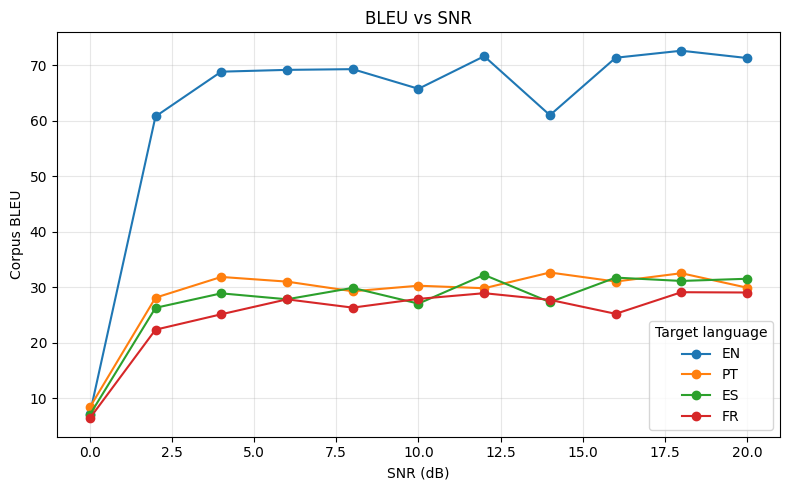

In [13]:
if not metrics_summary_df.empty:

    fig, ax = plt.subplots(figsize=(8, 5))

    for lang in LANGUAGES:
        lang_df = (
            metrics_summary_df[
                metrics_summary_df["language"] == lang
            ]
            .sort_values("snr_db")
        )

        if not lang_df.empty:
            ax.plot(
                lang_df["snr_db"],
                lang_df["bleu_mean"],
                marker="o",
                label=lang.upper(),
            )

    ax.set_title("BLEU vs SNR")
    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("Corpus BLEU")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Target language")
    fig.tight_layout()

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    bleu_plot_path = os.path.join(
        OUTPUT_DIR,
        "bleu_vs_snr.png",
    )
    fig.savefig(
        bleu_plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    # print("Saved:", bleu_plot_path)


## 13. Semantic similarity vs SNR

This plot shows how well sentence meaning is preserved as SNR changes.


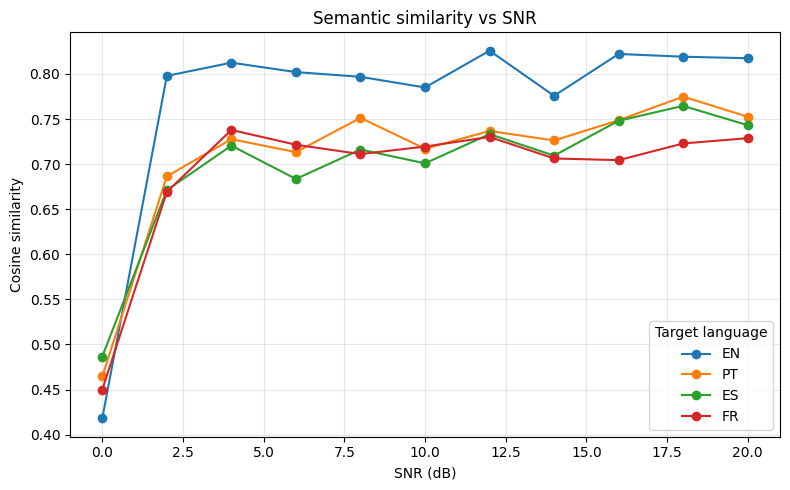

In [14]:
if not metrics_summary_df.empty:

    fig, ax = plt.subplots(figsize=(8, 5))

    for lang in LANGUAGES:
        lang_df = (
            metrics_summary_df[
                metrics_summary_df["language"] == lang
            ]
            .sort_values("snr_db")
        )

        if not lang_df.empty:
            ax.plot(
                lang_df["snr_db"],
                lang_df["semantic_similarity_mean"],
                marker="o",
                label=lang.upper(),
            )

    ax.set_title("Semantic similarity vs SNR")
    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("Cosine similarity")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Target language")
    fig.tight_layout()

    semantic_plot_path = os.path.join(
        OUTPUT_DIR,
        "semantic_similarity_vs_snr.png",
    )
    fig.savefig(
        semantic_plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    # print("Saved:", semantic_plot_path)


## 14. chrF++ vs SNR

chrF++ is useful for multilingual text because it measures character-level overlap and is less brittle than exact token matching.


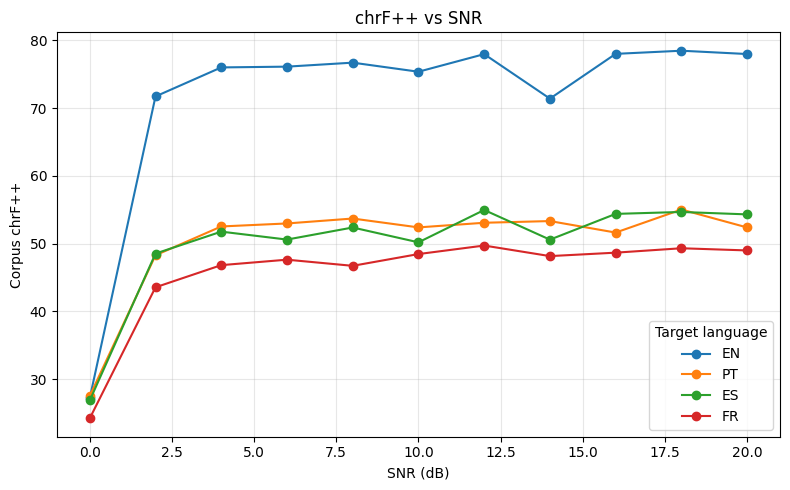

In [15]:
if not metrics_summary_df.empty:

    fig, ax = plt.subplots(figsize=(8, 5))

    for lang in LANGUAGES:
        lang_df = (
            metrics_summary_df[
                metrics_summary_df["language"] == lang
            ]
            .sort_values("snr_db")
        )

        if not lang_df.empty:
            ax.plot(
                lang_df["snr_db"],
                lang_df["chrf_mean"],
                marker="o",
                label=lang.upper(),
            )

    ax.set_title("chrF++ vs SNR")
    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("Corpus chrF++")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Target language")
    fig.tight_layout()

    chrf_plot_path = os.path.join(
        OUTPUT_DIR,
        "chrf_vs_snr.png",
    )
    fig.savefig(
        chrf_plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    # print("Saved:", chrf_plot_path)


## 15. Language comparison at one SNR

This bar chart makes it easy to compare EN/PT/ES/FR at a selected operating point.

By default it uses the highest evaluated SNR. Change `SNR_FOR_BAR` if another point is more useful.


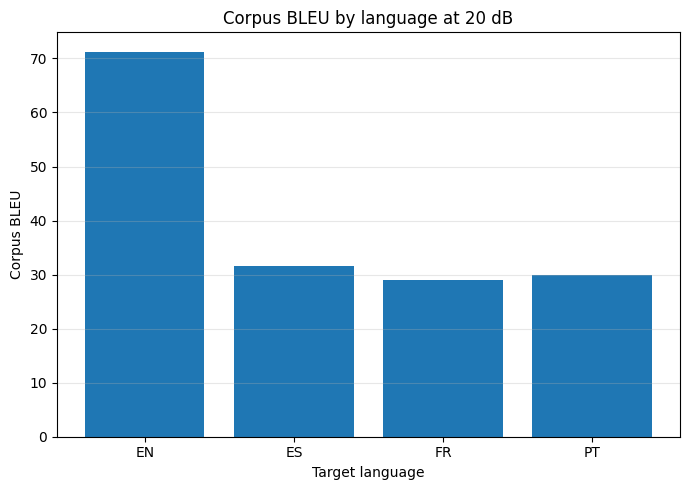

In [16]:
if not metrics_summary_df.empty:

    SNR_FOR_BAR = max(float(x) for x in SNR_DB)

    selected = (
        metrics_summary_df[
            metrics_summary_df["snr_db"] == SNR_FOR_BAR
        ]
        .copy()
        .sort_values("language")
    )

    if selected.empty:
        print(
            f"No metric rows found for SNR={SNR_FOR_BAR:g} dB."
        )
    else:
        fig, ax = plt.subplots(figsize=(7, 5))

        ax.bar(
            selected["language"].str.upper(),
            selected["bleu_mean"],
        )

        ax.set_title(
            f"Corpus BLEU by language at {SNR_FOR_BAR:g} dB"
        )
        ax.set_xlabel("Target language")
        ax.set_ylabel("Corpus BLEU")
        ax.grid(
            True,
            axis="y",
            alpha=0.3,
        )
        fig.tight_layout()

        bar_plot_path = os.path.join(
            OUTPUT_DIR,
            f"bleu_by_language_{SNR_FOR_BAR:g}dB.png",
        )
        fig.savefig(
            bar_plot_path,
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()

        # print("Saved:", bar_plot_path)


## 16. Optional: exact match and token accuracy vs SNR

These are stricter metrics than BLEU/semantic similarity. They are useful diagnostically, especially for English reconstruction.


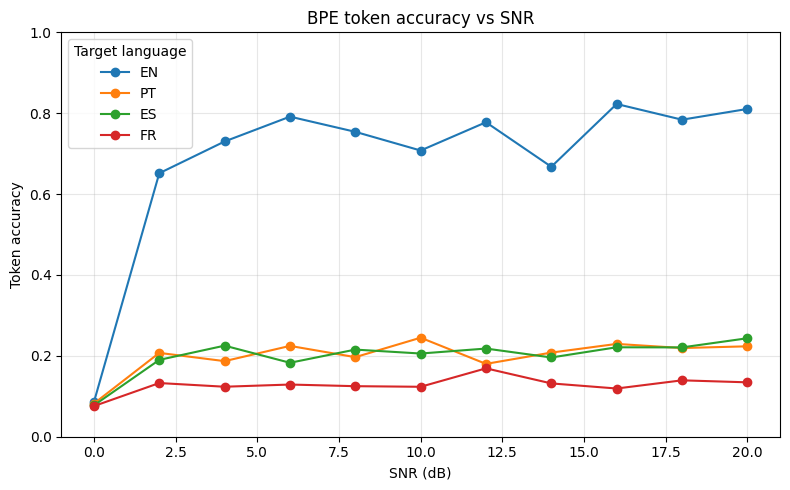

In [17]:
if not metrics_summary_df.empty:

    fig, ax = plt.subplots(figsize=(8, 5))

    for lang in LANGUAGES:
        lang_df = (
            metrics_summary_df[
                metrics_summary_df["language"] == lang
            ]
            .sort_values("snr_db")
        )

        if not lang_df.empty:
            ax.plot(
                lang_df["snr_db"],
                lang_df["token_accuracy_mean"],
                marker="o",
                label=lang.upper(),
            )

    ax.set_title("BPE token accuracy vs SNR")
    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel("Token accuracy")
    ax.set_ylim(0.0, 1.0)
    ax.grid(True, alpha=0.3)
    ax.legend(title="Target language")
    fig.tight_layout()

    token_plot_path = os.path.join(
        OUTPUT_DIR,
        "token_accuracy_vs_snr.png",
    )
    fig.savefig(
        token_plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    # print("Saved:", token_plot_path)


## 17. Inspect the same sample in four languages


In [18]:
if not predictions_df.empty:

    example_id = predictions_df.iloc[0]["id"]

    display(
        predictions_df[
            predictions_df["id"] == example_id
        ][
            [
                "snr_db",
                "trial",
                "source_en",
                "language",
                "reference",
                "prediction",
            ]
        ]
    )


,snr_db,trial,source_en,language,reference,prediction
0,0.0,1,to do so would be like saying to someone bent ...,en,to do so would be like saying to someone bent ...,so it would so to be the part of anyone of the...
20,0.0,1,to do so would be like saying to someone bent ...,pt,fazer isso seria como dizer a alguém decidido ...,"por isso, gostaria de dizer que todos os estad..."
40,0.0,1,to do so would be like saying to someone bent ...,es,hacerlo sería como decirle a alguien decidido ...,"por lo tanto, lo que sería decir que todos los..."
60,0.0,1,to do so would be like saying to someone bent ...,fr,ce serait comme dire à quelqu'un déterminé à t...,il ne s'agit donc d'une partie de ce que l'ue ...
80,2.0,1,to do so would be like saying to someone bent ...,en,to do so would be like saying to someone bent ...,to do so would be as to say like saying bent a...
100,2.0,1,to do so would be like saying to someone bent ...,pt,fazer isso seria como dizer a alguém decidido ...,"por isso, isso seria dizer que, em primeiro lu..."
120,2.0,1,to do so would be like saying to someone bent ...,es,hacerlo sería como decirle a alguien decidido ...,"por lo tanto, lo que sería decir como decir co..."
140,2.0,1,to do so would be like saying to someone bent ...,fr,ce serait comme dire à quelqu'un déterminé à t...,"pour le fait, c'est-à-dire comme d'autre part,..."
160,4.0,1,to do so would be like saying to someone bent ...,en,to do so would be like saying to someone bent ...,to do so would be like to say anyone bent upon...
180,4.0,1,to do so would be like saying to someone bent ...,pt,fazer isso seria como dizer a alguém decidido ...,"por isso, gostaria de dizer que, em primeiro l..."


## 18. Save outputs

In [20]:
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True,
)

predictions_path = os.path.join(
    OUTPUT_DIR,
    "predictions.csv",
)

metrics_path = os.path.join(
    OUTPUT_DIR,
    "metrics.csv",
)

predictions_df.to_csv(
    predictions_path,
    index=False,
)

if not metrics_df.empty:
    metrics_df.to_csv(
        metrics_path,
        index=False,
    )

print("Saved:", predictions_path)

if not metrics_df.empty:
    print("Saved:", metrics_path)


if 'metrics_summary_df' in globals() and not metrics_summary_df.empty:
    metrics_summary_path = os.path.join(
        OUTPUT_DIR,
        "metrics_summary_29_09.csv",
    )

    metrics_summary_df.to_csv(
        metrics_summary_path,
        index=False,
    )

    print("Saved:", metrics_summary_path)


Saved: results/multilingual_shared_tx/predictions.csv
Saved: results/multilingual_shared_tx/metrics.csv
Saved: results/multilingual_shared_tx/metrics_summary_29_09.csv


## Why this notebook is preferable

This notebook does not implement a second version of the DeepSC data, BPE, channel, decoder, checkpoint, or metric logic.

If those functions change in branch `all`, the notebook automatically uses the repository version after the next kernel restart.

The experiment-specific guarantee remains:

> **one `send_through_channel()` call → same `Rx_sig` reused for all language-control tokens.**
